<img src="https://fedesarrollo.org.co/logo-Fede.png" alt="Fedesarrollo" style="float: right; width: 300px; height: auto;">
<img src="https://upload.wikimedia.org/wikipedia/commons/f/f9/Logo_BID_Espa%C3%B1ol.png" alt="Banco Interamericano de Desarrollo" style="float: right; width: 220px; height: auto;">

# Figuras de la presentación

Editor: Juan Diego Heredia Niño - jheredia@fedesarrollo.org.co

Septiembre 2026

### Importar librerías

La siguiente celda marca el inicio de un nuevo bloque de trabajo independiente:

**Librerías utilizadas:**
- `pandas` y `numpy`: para manipulación y análisis de datos estructurados.
- `matplotlib.pyplot`: para las figuras.
- `openpyxl`: para leer los valores calculados del libro de resultados.

In [1]:
import pandas as pd
import numpy as np
import openpyxl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from collections import defaultdict

### Configuración de rutas

Carga las rutas del proyecto y las opciones globales desde `config.py`, instalado como
paquete editable en la raíz del proyecto.

In [2]:
from config import (raw, temp, processed, figures, colores_industrias, random_state,
                    valor_inicial, valor_final, porcentaje_min, porcentaje_max,
                    num_iteraciones, top_n_industrias)

### Parámetros

Define el escenario, las paletas de las dos áreas apiladas y el umbral de la figura de industrias.

Las dos primeras figuras se armaron originalmente en Excel; aquí se reproducen en matplotlib,
por lo que su aspecto cambia respecto del deck publicado. Las series que las alimentan son las
mismas. La tercera reconstruye una figura cuyo código no se conserva.
Ver `tools/markdown/AUDITORIA_MIGRACION.md`, hallazgo 2.7.

In [3]:
escenario = '15'

colores_exportaciones = ['#6B5B95', '#A99BC1']
colores_pib = ['#7F9F55', '#A9C58B']

top_n_industrias = 10

### Lectura de las series proyectadas

Carga del libro de resultados la trayectoria anual del producto interno bruto y de las
exportaciones, en su escenario vegetativo y con la ganancia adicional, y la convierte de pesos
constantes de 2015 a miles de millones de dólares de 2024.

In [4]:
archivo = raw / 'impacto_excel' / f'Nearshoring Resultados Númericos - V05 - {escenario}%.xlsx'
libro = openpyxl.load_workbook(archivo, data_only=True)

# Referencias de conversion: el libro trabaja en pesos de 2015
referencias = {
    fila[0]: fila[1]
    for fila in libro['Números'].iter_rows(min_row=1, max_row=45, values_only=True)
    if isinstance(fila[0], str) and isinstance(fila[1], (int, float))
}
deflactor = referencias['Deflactor 2024 a 2015 con base en IPC']
trm_2024 = referencias['TRM 2024 en dolares de 2024']

# Hoja1 guarda las series como texto, con encabezado en la tercera fila
columnas = ['anio', 'pib_vegetativo', 'pib_total', 'expo_veg_nt',
            'expo_vegetativas', 'delta_expo', 'total_expo_nt', 'total_expo']

df_series = pd.DataFrame([
    {nombre: float(fila[i]) for i, nombre in enumerate(columnas)}
    for fila in libro['Hoja1'].iter_rows(min_row=4, max_row=30, values_only=True)
    if fila[0] is not None and str(fila[0]).replace('.0', '').isdigit()
])
df_series['anio'] = df_series['anio'].astype(int)

# pesos de 2015 a miles de millones de dolares de 2024
for columna in columnas[1:]:
    df_series[columna] = df_series[columna] / deflactor / trm_2024 / 1_000_000_000

df_series['delta_pib'] = df_series['pib_total'] - df_series['pib_vegetativo']

print(df_series[['anio', 'expo_vegetativas', 'delta_expo', 'pib_vegetativo', 'delta_pib']].iloc[[0, -1]].to_string(index=False))

 anio  expo_vegetativas  delta_expo  pib_vegetativo  delta_pib
 2025             49.56        2.14          419.07       1.99
 2045             86.45      122.65          731.03     113.80


### Exportaciones y producto interno bruto proyectados

Las dos áreas apiladas de la presentación. La inferior es la trayectoria vegetativa y la
superior el efecto de la estrategia.

El bloque es el mismo para ambas, de modo que se define una vez y se invoca con la tabla de
parámetros.

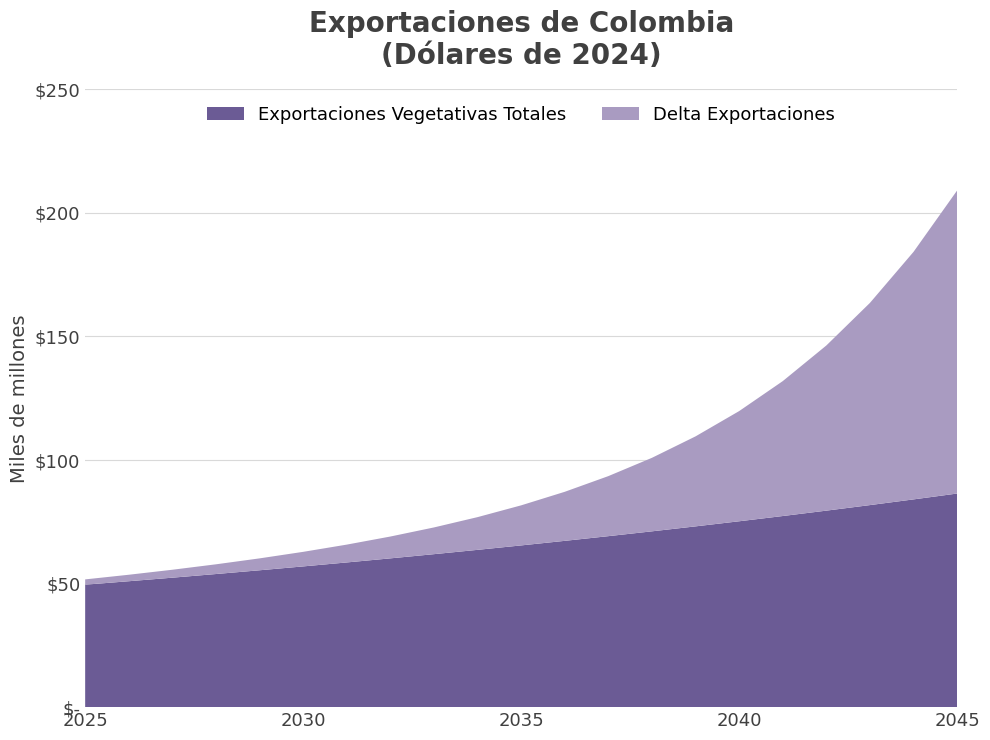

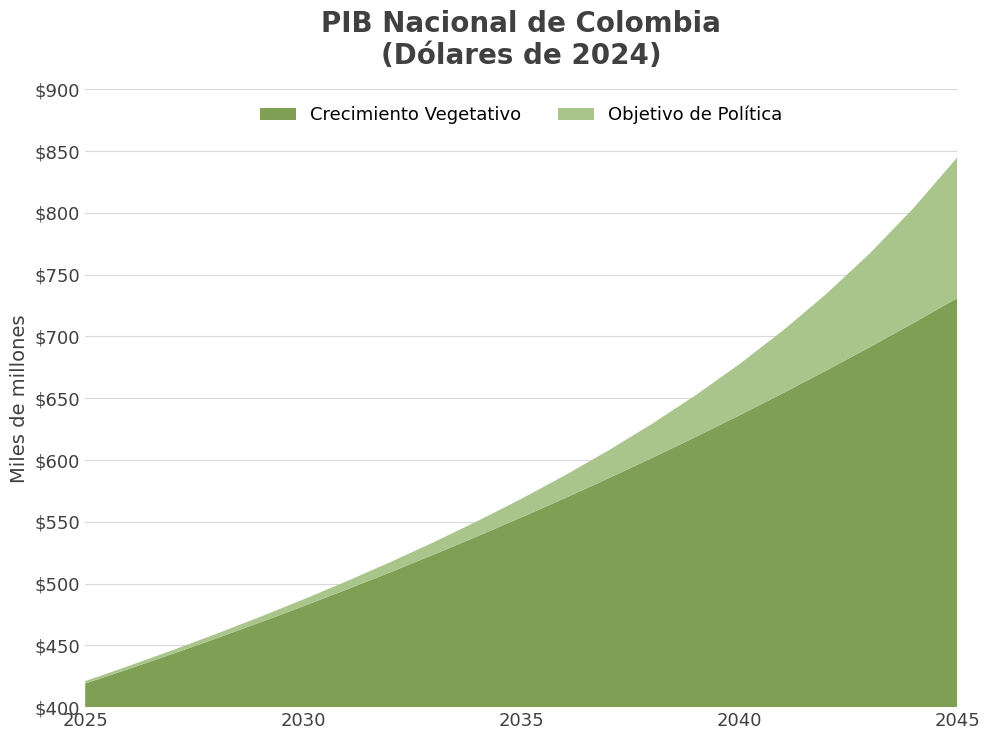

In [5]:
def area_apilada(series, etiquetas, colores, titulo, limites_y, archivo_salida):
    """Dibuja un area apilada de dos series anuales y la guarda en output/figures/deck."""
    fig, ax = plt.subplots(figsize=(10, 7.5))

    ax.stackplot(df_series['anio'], *series, labels=etiquetas, colors=colores)

    ax.set_title(titulo, fontsize=20, fontweight='bold', color='#404040', pad=18)
    ax.set_ylabel('Miles de millones', fontsize=14, color='#404040')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=2,
              frameon=False, fontsize=13)

    ax.set_xlim(df_series['anio'].min(), df_series['anio'].max())
    inicio_y, fin_y, paso_y = limites_y
    ax.set_ylim(inicio_y, fin_y)
    ax.set_yticks(range(inicio_y, fin_y + 1, paso_y))
    ax.set_xticks(range(2025, 2050, 5))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.0f}' if v else '$-'))
    ax.tick_params(axis='both', labelsize=13, colors='#404040', length=0)
    ax.grid(True, axis='y', color='#D9D9D9', linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ['top', 'right', 'bottom', 'left']:
        ax.spines[lado].set_visible(False)

    (figures / 'deck').mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(figures / 'deck' / archivo_salida, dpi=150, bbox_inches='tight')
    plt.show()


# tabla de parametros: series, etiquetas, colores, titulo, limites del eje y archivo de salida.
# los limites replican los cortes del eje que tenian las figuras originales en Excel
parametros_figuras = [
    (['expo_vegetativas', 'delta_expo'],
     ['Exportaciones Vegetativas Totales', 'Delta Exportaciones'],
     colores_exportaciones,
     'Exportaciones de Colombia\n(Dólares de 2024)',
     (0, 250, 50),
     'Imagen 1.png'),
    (['pib_vegetativo', 'delta_pib'],
     ['Crecimiento Vegetativo', 'Objetivo de Política'],
     colores_pib,
     'PIB Nacional de Colombia\n(Dólares de 2024)',
     (400, 900, 50),
     'Imagen 2.png'),
]

for cols, etiquetas, colores, titulo, limites_y, salida in parametros_figuras:
    area_apilada([df_series[c] for c in cols], etiquetas, colores, titulo, limites_y, salida)

### Ganancia exportadora por industria

Área apilada de la participación acumulada de la ganancia exportadora por industria CIIU, para las
diez de mayor peso. La mecánica es la del proyecto original, conservada en
`reports/slide/originales/pipeline_proyecciones_industrias.ipynb`: las participaciones no se
calculan aquí, se leen, y con ellas se reparte entre industrias la trayectoria que marca el índice
normalizado.

$$\\text{Proyección}(t) = A + (B - A)\\cdot\\frac{I(t) - I(0)}{I(19) - I(0)},
\\qquad \\text{banda}_i(t) = \\text{Proyección}(t)\\times \\text{Share}_i$$

**Sobre la tabla de participaciones.** `resultados_ciiu_global.xlsx` es la salida de una corrida
del bootstrap segmentado cuyo código no se conserva, de modo que entra como insumo archivado y no
como paso reproducible de la cadena. Su columna `Share` es la suma de las tres hojas por tipo de
oportunidad, y hay industrias que aparecen en varias: el CIIU 0311, pesca marítima, está en las
tres, así que su 11,27% resulta de contarlo tres veces. Sobre el panel completo esa industria pesa
3,97%. La figura reproduce el entregable tal como se publicó; el hallazgo queda anotado en la
auditoría.

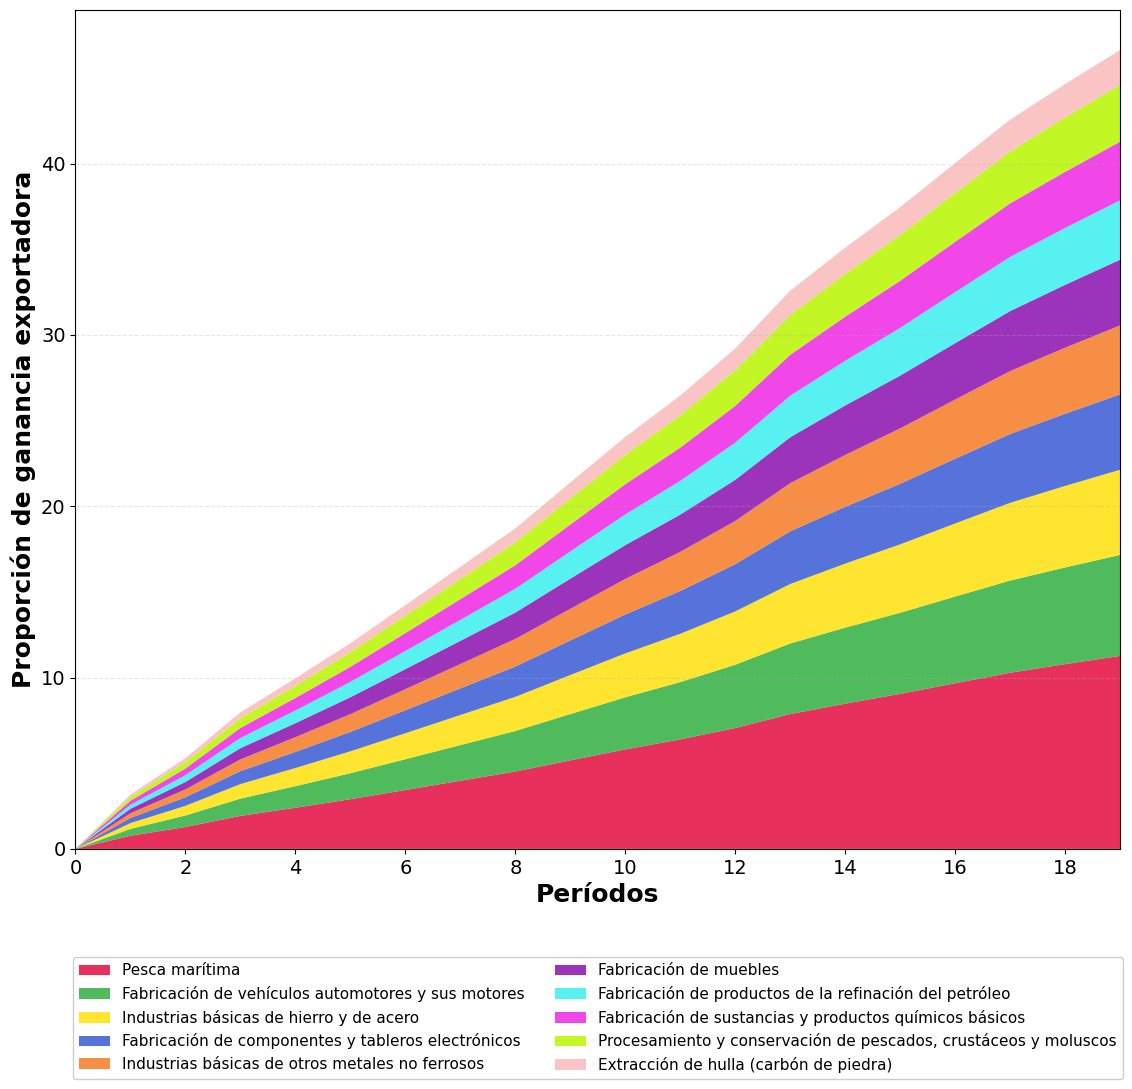

CIIU  Share                                                Descripción CIIU
0311   0.11                                                  Pesca marítima
2910   0.06              Fabricación de vehículos automotores y sus motores
2410   0.05                         Industrias básicas de hierro y de acero
2610   0.04              Fabricación de componentes y tableros electrónicos
2429   0.04                 Industrias básicas de otros metales no ferrosos
3110   0.04                                          Fabricación de muebles
1921   0.03          Fabricación de productos de la refinación del petróleo
2011   0.03          Fabricación de sustancias y productos químicos básicos
1012   0.03 Procesamiento y conservación de pescados, crustáceos y moluscos
0510   0.02                          Extracción de hulla (carbón de piedra)

Suma de las diez participaciones: 0.4663


In [6]:
df_participaciones = (
    pd.read_excel(raw / 'modelo' / 'resultados_ciiu_global.xlsx', sheet_name='Todos_CIIU')
    .dropna(subset=['CIIU'])
    .assign(CIIU=lambda d: d['CIIU'].astype(int).astype(str).str.zfill(4))
    .nlargest(top_n_industrias, 'Share')
    [['CIIU', 'Share']]
    .reset_index(drop=True)
)

# Nombres CIIU a cuatro digitos, los mismos rotulos que muestra la presentacion
df_nombres_ciiu = (
    pd.read_excel(raw / 'ciiu' / 'CIIU_Clasificacion_Actualizada.xlsx')
    .dropna(subset=['CIIU'])
    .assign(CIIU=lambda d: d['CIIU'].astype(int).astype(str).str.zfill(4))
    [['CIIU', 'Descripción CIIU']]
    .drop_duplicates('CIIU')
)

df_participaciones = df_participaciones.merge(df_nombres_ciiu, on='CIIU', how='left')

# Reescalado del indice entre el valor inicial y el final de la proyeccion
indices = pd.read_parquet(temp / 'modelo' / 'indices_normalizados_20anios.parquet')
indice_inicial = indices.loc[indices['periodo'] == 0, 'indice_normalizado'].values[0]
indice_final = indices.loc[indices['periodo'] == 19, 'indice_normalizado'].values[0]

indices['valor_total'] = valor_inicial + (valor_final - valor_inicial) * (
    (indices['indice_normalizado'] - indice_inicial) / (indice_final - indice_inicial)
)

# Cada banda es la trayectoria total multiplicada por la participacion constante de su industria
df_proyecciones = pd.DataFrame({
    fila['Descripción CIIU']: indices['valor_total'].to_numpy() * fila['Share']
    for _, fila in df_participaciones.iterrows()
})
df_proyecciones.insert(0, 'periodo', indices['periodo'].to_numpy())

industrias = df_participaciones['Descripción CIIU'].tolist()

fig, ax = plt.subplots(figsize=(12, 11))
ax.stackplot(df_proyecciones['periodo'],
             *[df_proyecciones[industria].to_numpy() for industria in industrias],
             labels=industrias,
             colors=colores_industrias[:len(industrias)],
             alpha=0.9)
ax.set_xlabel('Períodos', fontsize=18, fontweight='bold')
ax.set_ylabel('Proporción de ganancia exportadora', fontsize=18, fontweight='bold')
ax.legend(loc='upper center', fontsize=11, ncol=2, framealpha=0.95, bbox_to_anchor=(0.5, -0.12))
ax.grid(True, alpha=0.3, axis='y', linestyle='--', linewidth=0.8)
ax.set_xlim(0, 19)
ax.set_xticks(range(0, 20, 2))
ax.tick_params(axis='both', which='major', labelsize=14)

(figures / 'deck').mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(figures / 'deck' / 'Imagen 4.png', dpi=300, bbox_inches='tight')
plt.show()

print(df_participaciones.to_string(index=False))
print(f"\nSuma de las diez participaciones: {df_participaciones['Share'].sum():.4f}")

### Series de exportaciones de los países de referencia

Cuatro paneles con la serie anual de exportaciones totales de Colombia, Costa Rica, República
Dominicana y México, que son los países sobre los que se construye el índice normalizado.

La fuente es el mismo extracto de WITS que alimenta `01_cleaning/12_indice_normalizado`. Los
títulos conservan el nombre del país tal como viene en el campo `ReporterName`, en inglés, igual
que en la figura publicada.

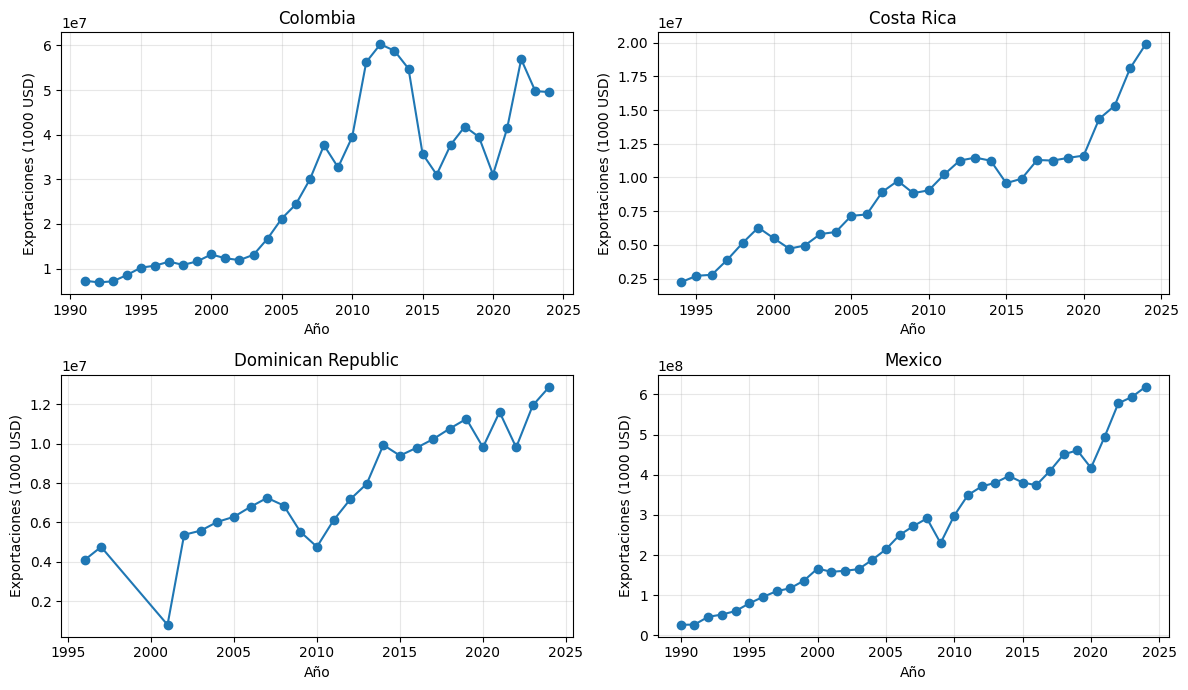

                     min   max  size
pais                                
Colombia            1991  2024    34
Costa Rica          1994  2024    31
Dominican Republic  1996  2024    26
Mexico              1990  2024    35


In [7]:
df_wits = pd.read_csv(
    raw / 'comentarios' / '3004985_1C4043D0-F' / 'DataJobID-3004985_3004985_howExportGrows.csv',
    encoding='latin-1',
)
df_wits['ProductCode'] = df_wits['ProductCode'].astype(str).str.strip()

df_expo_paises = (
    df_wits
    .query("ProductCode == 'Total' and PartnerISO3 == 'WLD' and TradeFlowName == 'Export'")
    [['ReporterName', 'Year', 'TradeValue in 1000 USD']]
    .rename(columns={'ReporterName': 'pais', 'Year': 'anio', 'TradeValue in 1000 USD': 'exportaciones'})
    .sort_values(['pais', 'anio'])
)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (pais, df_pais) in zip(axes.flatten(), df_expo_paises.groupby('pais')):
    ax.plot(df_pais['anio'], df_pais['exportaciones'], marker='o')
    ax.set_title(pais)
    ax.set_xlabel('Año')
    ax.set_ylabel('Exportaciones (1000 USD)')
    ax.grid(True, alpha=0.3)

(figures / 'deck').mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(figures / 'deck' / 'expos.png', dpi=150, bbox_inches='tight')
plt.show()

print(df_expo_paises.groupby('pais')['anio'].agg(['min', 'max', 'size']).to_string())